## Test the three Way 1 Multinomial Classification

### Feature Name Change Function

In [23]:
def human_readable_feature(name: str) -> str:
    """
    Convert pipeline feature names into human-readable labels.
    """
    mapping = {
        # Main Concept Features
        "total_utterances": "Total Number of Utterances",
        "distance_to_centroid": "Distance to Centroid",
        "num_unique_main_concepts": "Number of Unique MC",
        "num_total_main_concepts": "Number of Total MC",
        "unique_main_concept_match_ratio": "Unique MC Match Ratio",
        "total_main_concept_match_ratio": "Total MC Match Ratio",
        "sequence_score_mainconcept": "Sequence Score",
        "local_coherence_mainconcept": "Local Coherence Rate",
        "global_coherence_mainconcept": "Global Coherence Rate",

        # Coherence Error Counts
        "num_topic_switching": "Number of Topic Switching Errors",
        "num_missing_referent": "Number of Missing Referent Errors",
        "num_tangential_utterance": "Number of Tangential Errors",
        "num_propositional_repetition": "Number of Propositional Repetitions",
        "num_filler": "Number of Filler Errors",
        "num_conceptual_incongruence": "Number of Conceptual Incongruences",
        "num_coherent": "Number of Coherent Utterances",

        # Coherence Error Ratios
        "ratio_topic_switching_percent": "Topic Switching Error Rate",
        "ratio_missing_referent_percent": "Missing Referent Error Rate",
        "ratio_tangential_utterance_percent": "Tangential Utterance Rate",
        "ratio_propositional_repetition_percent": "Propositional Repetition Rate",
        "ratio_filler_percent": "Filler Rate",
        "ratio_conceptual_incongruence_percent": "Conceptual Incongruence Rate",
        "ratio_coherent_percent": "Coherent Utterance Rate",
    }

    return mapping.get(name, name.replace("_", " ").title())


def convert_feature_list(features):
    """
    Convert a list of feature names to human-readable labels.
    """
    return [human_readable_feature(f) for f in features]

In [3]:
import pandas as pd
import numpy as np

dementia_features_df = pd.read_csv('../data/classification/3_mainconcept_features_dem_qsub.csv') 
aphasia_features_df = pd.read_csv('../data/classification/3_mainconcept_features_aph_qsub.csv')
controls_features_df = pd.read_csv('../data/classification/3_mainconcept_features_ctr_qsub.csv')   # Replace with the actual filename
print(controls_features_df.info())
  # Replace with the actual filename
print(dementia_features_df.info())
print(aphasia_features_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113 entries, 0 to 112
Data columns (total 24 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   participant                             113 non-null    object 
 1   total_utterances                        113 non-null    int64  
 2   distance_to_centroid                    113 non-null    float64
 3   num_unique_main_concepts                113 non-null    int64  
 4   num_total_main_concepts                 113 non-null    int64  
 5   unique_main_concept_match_ratio         113 non-null    float64
 6   total_main_concept_match_ratio          113 non-null    float64
 7   sequence_score_mainconcept              113 non-null    float64
 8   local_coherence_mainconcept             113 non-null    float64
 9   global_coherence_mainconcept            113 non-null    float64
 10  num_topic_switching                     113 non-null    int64 

In [4]:
participants_df = pd.read_csv('../data/classification/combined_patient_data_111725.csv')  
print(participants_df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Corpus             309 non-null    object 
 1   participant        309 non-null    object 
 2   age                302 non-null    object 
 3   sex                309 non-null    object 
 4   diagnosis          309 non-null    object 
 5   WAB score          102 non-null    float64
 6   standardized MOCA  132 non-null    float64
 7   gen_diagnosis      309 non-null    object 
dtypes: float64(2), object(6)
memory usage: 19.4+ KB
None


In [5]:
# Conditionally create combined ID only if Participant_Code starts with a numerical value (digit)
participants_df['combined_id'] = np.where(
    participants_df['participant'].str[0].str.isdigit(),
    participants_df['Corpus'].str.lower().str.strip() + participants_df['participant'].str.strip(),
    participants_df['participant'].str.strip()  # Fallback to just participant code if condition not met
)

participants_df['combined_id'] = participants_df['combined_id'].str.lower()

# Output the combined IDs
print(participants_df['combined_id'].tolist())

['delaware02-1', 'delaware03-1', 'delaware04-1', 'delaware05-1', 'delaware07-1', 'delaware08-1', 'delaware101-1', 'delaware12-1', 'delaware13-1', 'delaware200-1', 'delaware201-1', 'delaware203-1', 'delaware204-1', 'delaware208-1', 'delaware209-1', 'delaware214-1', 'delaware218-1', 'delaware220-1', 'delaware221-1', 'delaware224-1', 'delaware225-1', 'delaware226-1', 'delaware227-1', 'delaware228-1', 'delaware229-1', 'delaware233-1', 'delaware234-1', 'delaware235-1', 'delaware24-1', 'delaware244-1', 'delaware25-1', 'delaware270-1', 'delaware271-1', 'delaware276-1', 'delaware278-1', 'delaware279-1', 'delaware29-1', 'delaware30-1', 'delaware35-1', 'delaware36-1', 'delaware37-1', 'delaware38-1', 'delaware39-1', 'delaware42-1', 'delaware44-1', 'delaware45-1', 'delaware46-1', 'delaware48-1', 'delaware60-1', 'delaware62-1', 'delaware65-1', 'delaware67-1', 'delaware70-1', 'delaware77-1', 'delaware81-1', 'delaware84-1', 'delaware86-1', 'delaware87-1', 'delaware90-1', 'delaware92-1', 'delaware93-1

In [6]:
aphasia_df = participants_df[participants_df['gen_diagnosis'] == 'Aphasia']
dementia_df = participants_df[participants_df['gen_diagnosis'] == 'Dementia']
controls_df = participants_df[participants_df['gen_diagnosis'] == 'Control']
print(dementia_df.info())
print(aphasia_df.info())
print(controls_df.info())

<class 'pandas.core.frame.DataFrame'>
Index: 94 entries, 113 to 206
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Corpus             94 non-null     object 
 1   participant        94 non-null     object 
 2   age                87 non-null     object 
 3   sex                94 non-null     object 
 4   diagnosis          94 non-null     object 
 5   WAB score          0 non-null      float64
 6   standardized MOCA  66 non-null     float64
 7   gen_diagnosis      94 non-null     object 
 8   combined_id        94 non-null     object 
dtypes: float64(2), object(7)
memory usage: 7.3+ KB
None
<class 'pandas.core.frame.DataFrame'>
Index: 102 entries, 207 to 308
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Corpus             102 non-null    object 
 1   participant        102 non-null    object 
 2   age              

In [7]:
aphasia_features_df['participant'] = aphasia_features_df['participant'].str.lower()
dementia_features_df['participant'] = dementia_features_df['participant'].str.lower()
controls_features_df['participant'] = controls_features_df['participant'].str.lower()

In [8]:
# unique IDs from each side
p_ids = set(aphasia_df['combined_id'])
f_ids = set(aphasia_features_df['participant'])
print(len(p_ids)), 
print(len(f_ids))

# who is in participants_df but NOT in controls_features_df
missing_in_features = p_ids - f_ids

# who is in controls_features_df but NOT in participants_df
missing_in_participants = f_ids - p_ids

print("Missing in aphasia_features_df:", missing_in_features)
print("Missing in participants_df:", missing_in_participants)

102
102
Missing in aphasia_features_df: set()
Missing in participants_df: set()


In [11]:
from collections import Counter
dementia_features_df = pd.read_csv('../data/classification/3_mainconcept_features_dem_qsub.csv') 
dementia_features_df['participant'] = dementia_features_df['participant'].str.lower()# Conditionally create combined ID only if Participant_Code starts with a numerical value (digit)
dementia_features_df['participant'] = np.where(
    dementia_features_df['participant'].str[0].str.isdigit(),
    "delaware"+ dementia_features_df['participant'].str.strip(),
    dementia_features_df['participant'].str.strip()  # Fallback to just participant code if condition not met
)

print(dementia_features_df['participant'].tolist())
print(len(dementia_features_df))

missing_in_metadata = Counter(dementia_features_df['participant']) 
print(missing_in_metadata)

['baycrest11634', 'delaware22-1', 'rbn7927a', 'delaware75-1', 'delaware64-1', 'baycrest12828', 'jre5043a', 'baycrest2103', 'delaware32-1', 'delaware23-1', 'delaware232-1', 'due3951a', 'delaware18-1', 'baycrest8538', 'baycrest12756', 'bdy3628a', 'baycrest12814', 'kcr7045a', 'delaware19-1', 'delaware277-1', 'delaware47-1', 'delaware50-1', 'delaware14-1', 'delaware216-1', 'bmn3031b', 'bbw8512a', 'delaware52-1', 'lby4645a', 'delaware58-1', 'dcr7644a', 'delaware59-1', 'baycrest11976', 'delaware88-1', 'mvs4058a', 'rcl5752', 'delaware01-1', 'delaware09-1', 'delaware10-1', 'delaware17-1', 'emh9057a', 'amr6628a', 'jks7696a', 'delaware11-1', 'tbd4254a', 'delaware31-1', 'delaware95-1', 'hwn0674a', 'delaware54-1', 'delaware61-1', 'delaware63-1', 'jbh5314a', 'delaware79-1', 'delaware68-1', 'lrw4117a', 'delaware43-1', 'baycrest12257', 'delaware16-1', 'delaware21-1', 'delaware34-1', 'chp4775a', 'delaware27-1', 'nhe3782a', 'delaware71-1', 'baycrest12813', 'delaware78-1', 'delaware06-1', 'bfi6092a', 'd

In [12]:
# unique IDs from each side
p_ids = set(dementia_df['combined_id'])
f_ids = set(dementia_features_df['participant'])

# who is in participants_df but NOT in controls_features_df
missing_in_features = p_ids - f_ids

# who is in controls_features_df but NOT in participants_df
missing_in_participants = f_ids - p_ids

print("Missing in dementia_features_df:", missing_in_features)
print("Missing in participants_df:", missing_in_participants)

Missing in dementia_features_df: set()
Missing in participants_df: set()


In [13]:
aphasia_df['participant'] = aphasia_df['combined_id']
aphasia_df = aphasia_df.drop(columns=['combined_id'])

aphasia_combined_df = pd.merge(aphasia_df, aphasia_features_df, on='participant', how='inner')
print(len(aphasia_df))
print(len(aphasia_features_df))
aphasia_combined_df.info()

102
102
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 102 entries, 0 to 101
Data columns (total 31 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Corpus                                  102 non-null    object 
 1   participant                             102 non-null    object 
 2   age                                     102 non-null    object 
 3   sex                                     102 non-null    object 
 4   diagnosis                               102 non-null    object 
 5   WAB score                               102 non-null    float64
 6   standardized MOCA                       0 non-null      float64
 7   gen_diagnosis                           102 non-null    object 
 8   total_utterances                        102 non-null    int64  
 9   distance_to_centroid                    102 non-null    float64
 10  num_unique_main_concepts                102 non-null  

/scratch/ipykernel_1899091/3901510765.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  aphasia_df['participant'] = aphasia_df['combined_id']


In [14]:
dementia_df['participant'] = dementia_df['combined_id']
dementia_df = dementia_df.drop(columns=['combined_id'])

dementia_combined_df = pd.merge(dementia_df, dementia_features_df, on='participant', how='inner')
print(len(dementia_df))
# print(len(dementia_features_df))
dementia_combined_df.info()

94
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 94 entries, 0 to 93
Data columns (total 31 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Corpus                                  94 non-null     object 
 1   participant                             94 non-null     object 
 2   age                                     87 non-null     object 
 3   sex                                     94 non-null     object 
 4   diagnosis                               94 non-null     object 
 5   WAB score                               0 non-null      float64
 6   standardized MOCA                       66 non-null     float64
 7   gen_diagnosis                           94 non-null     object 
 8   total_utterances                        94 non-null     int64  
 9   distance_to_centroid                    94 non-null     float64
 10  num_unique_main_concepts                94 non-null     int64

/scratch/ipykernel_1899091/2793744067.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  dementia_df['participant'] = dementia_df['combined_id']


In [15]:
controls_df['participant'] = controls_df['combined_id']
controls_df = controls_df.drop(columns=['combined_id'])

controls_combined_df = pd.merge(controls_df, controls_features_df, on='participant', how='inner')
controls_combined_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 113 entries, 0 to 112
Data columns (total 31 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Corpus                                  113 non-null    object 
 1   participant                             113 non-null    object 
 2   age                                     113 non-null    object 
 3   sex                                     113 non-null    object 
 4   diagnosis                               113 non-null    object 
 5   WAB score                               0 non-null      float64
 6   standardized MOCA                       66 non-null     float64
 7   gen_diagnosis                           113 non-null    object 
 8   total_utterances                        113 non-null    int64  
 9   distance_to_centroid                    113 non-null    float64
 10  num_unique_main_concepts                113 non-null    int64 

/scratch/ipykernel_1899091/245591086.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  controls_df['participant'] = controls_df['combined_id']


In [16]:
all_df = pd.concat([dementia_combined_df, aphasia_combined_df, controls_combined_df], ignore_index=True)
all_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 309 entries, 0 to 308
Data columns (total 31 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   Corpus                                  309 non-null    object 
 1   participant                             309 non-null    object 
 2   age                                     302 non-null    object 
 3   sex                                     309 non-null    object 
 4   diagnosis                               309 non-null    object 
 5   WAB score                               102 non-null    float64
 6   standardized MOCA                       132 non-null    float64
 7   gen_diagnosis                           309 non-null    object 
 8   total_utterances                        309 non-null    int64  
 9   distance_to_centroid                    309 non-null    float64
 10  num_unique_main_concepts                309 non-null    int64 

In [17]:
columns_to_drop = ['sex','Corpus','WAB score', 'diagnosis', 'age', 'standardized MOCA', ]
num_df = all_df.drop(columns=columns_to_drop)
num_cols = num_df.columns
print(num_cols)

Index(['participant', 'gen_diagnosis', 'total_utterances',
       'distance_to_centroid', 'num_unique_main_concepts',
       'num_total_main_concepts', 'unique_main_concept_match_ratio',
       'total_main_concept_match_ratio', 'sequence_score_mainconcept',
       'local_coherence_mainconcept', 'global_coherence_mainconcept',
       'num_topic_switching', 'ratio_topic_switching_percent',
       'num_missing_referent', 'ratio_missing_referent_percent',
       'num_tangential_utterance', 'ratio_tangential_utterance_percent',
       'num_propositional_repetition',
       'ratio_propositional_repetition_percent', 'num_filler',
       'ratio_filler_percent', 'num_conceptual_incongruence',
       'ratio_conceptual_incongruence_percent', 'num_coherent',
       'ratio_coherent_percent'],
      dtype='object')


In [18]:
aph_df = num_df[num_df['gen_diagnosis'] == 'Aphasia']
dem_df = num_df[num_df['gen_diagnosis'] == 'Dementia']
ctrl_df = num_df[num_df['gen_diagnosis'] == 'Control']


print(f"Number of patients: {len(aph_df)}")
print(f"Number of controls: {len(dem_df)}")
print(f"Number of controls: {len(ctrl_df)}")

Number of patients: 102
Number of controls: 94
Number of controls: 113


In [19]:
import numpy as np
import pandas as pd

# columns to scale: all numeric except the label column(s)
num_cols = num_df.select_dtypes(include='number').columns.tolist()
for c in ['group']:
    if c in num_cols:
        num_cols.remove(c)

# fit params on the whole df
means = num_df[num_cols].mean()
stds  = num_df[num_cols].std(ddof=0).replace(0, np.nan)  # avoid div-by-zero

# normalized copy
df_z = all_df.copy()
df_z[num_cols] = (num_df[num_cols] - means) / stds

# if you prefer to keep zero-variance columns as 0 instead of NaN:
df_z[num_cols] = df_z[num_cols].fillna(0)

# split back to groups (normalized)
dem_df_z = df_z[df_z['gen_diagnosis'] == 'Dementia'].copy()
aph_df_z = df_z[df_z['gen_diagnosis'] == 'Aphasia'].copy()
ctl_df_z = df_z[df_z['gen_diagnosis'] == 'Control'].copy()

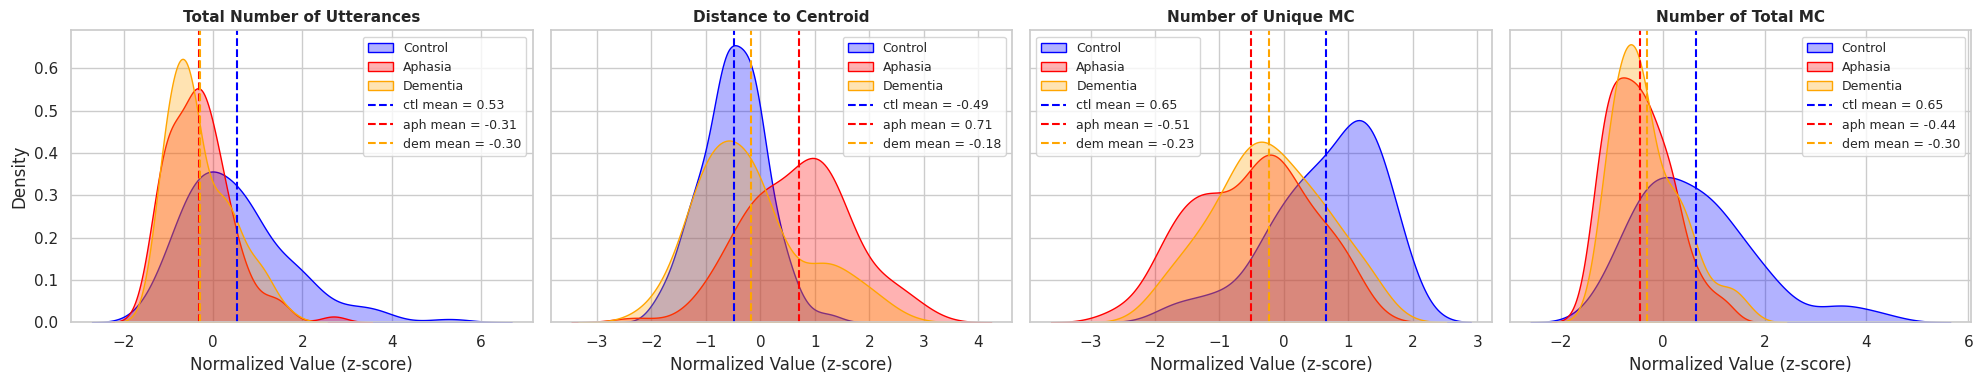

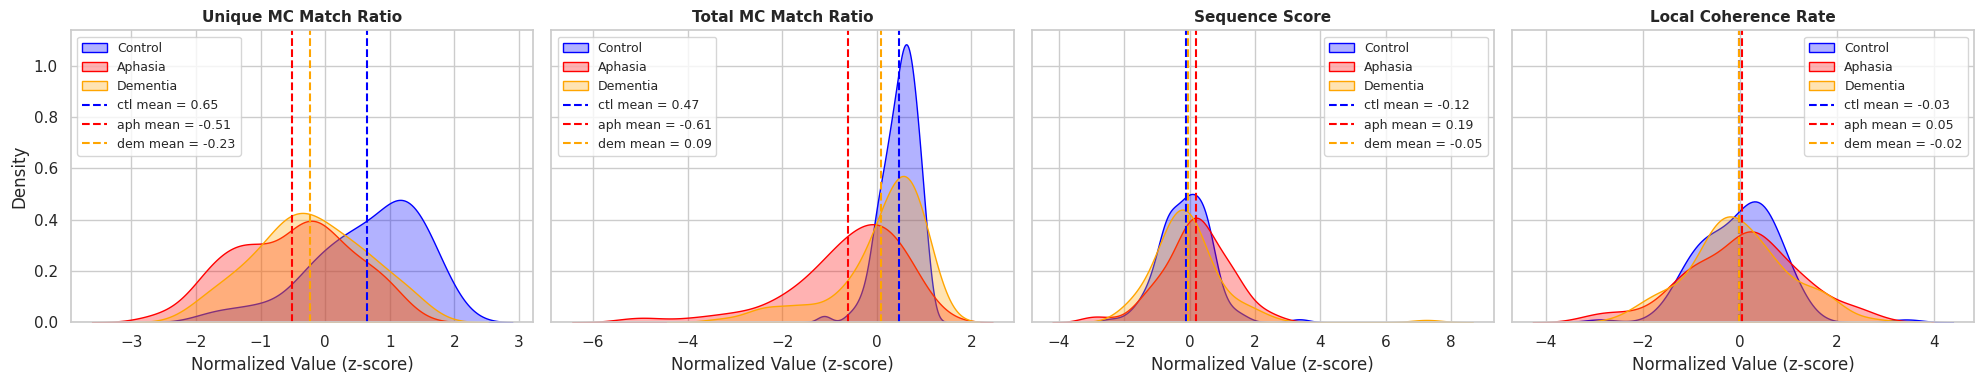

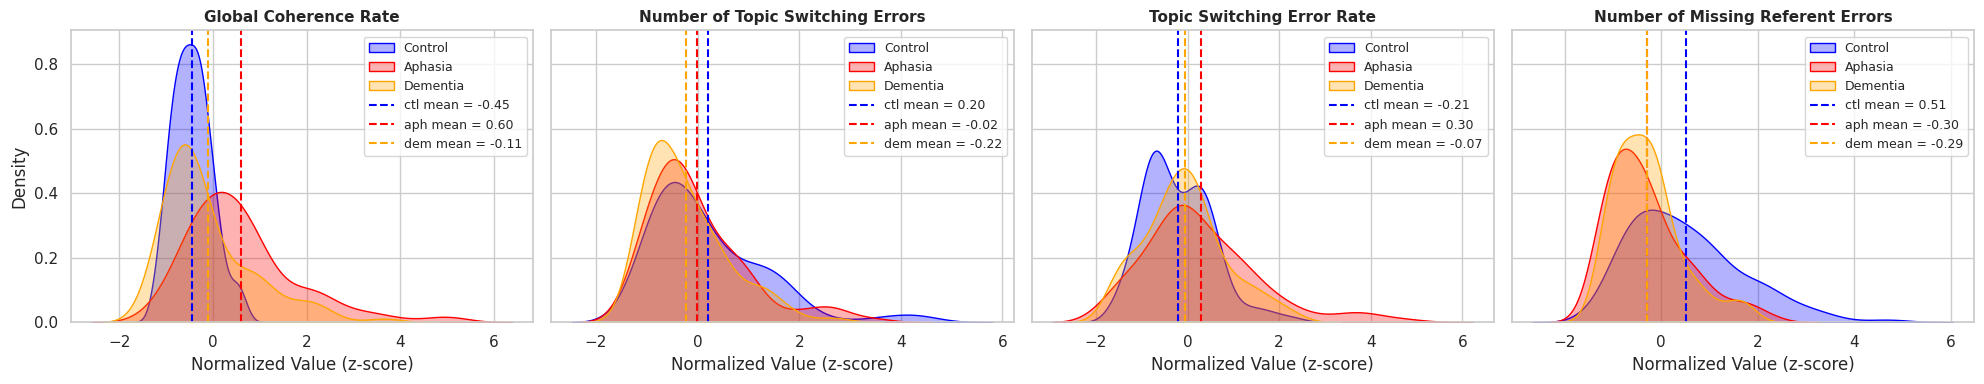

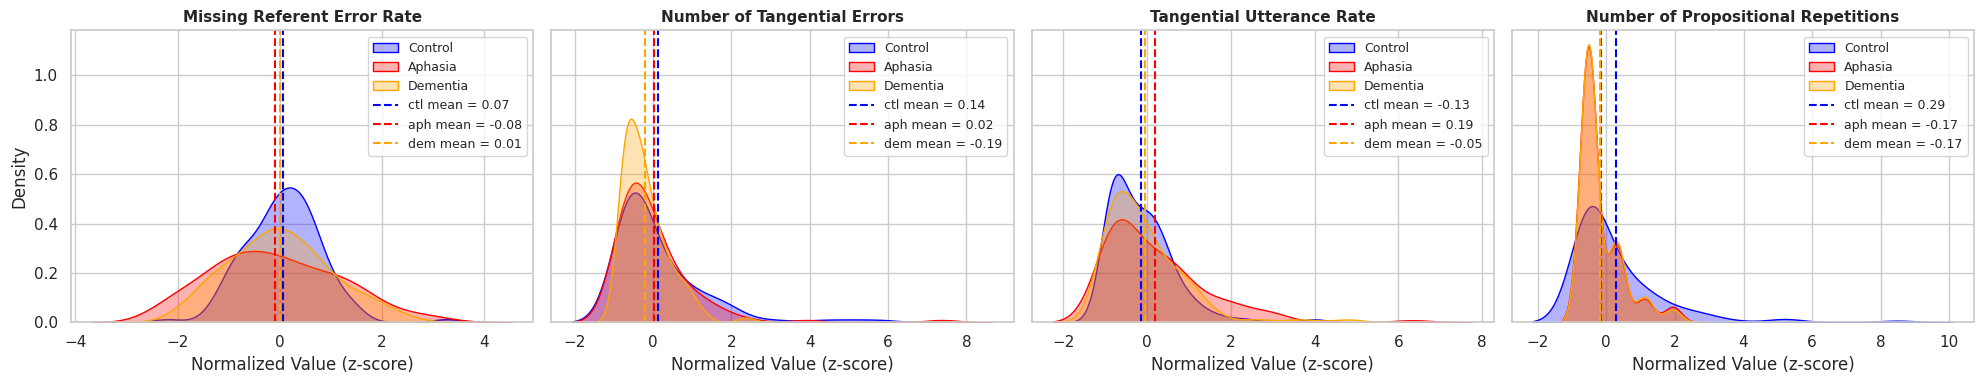

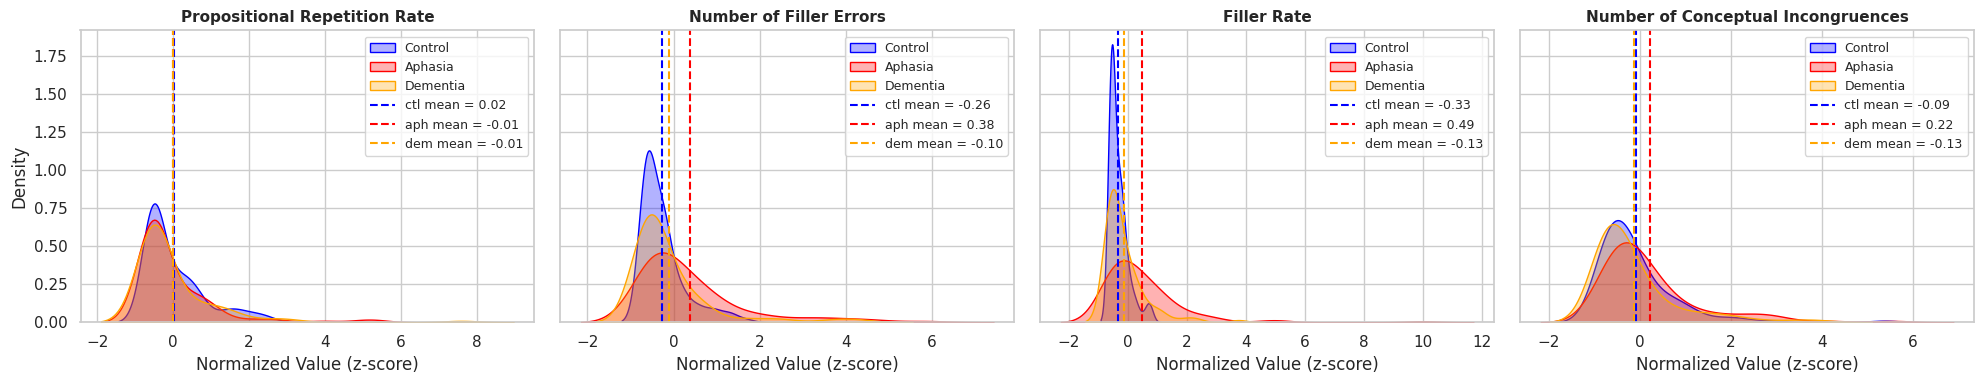

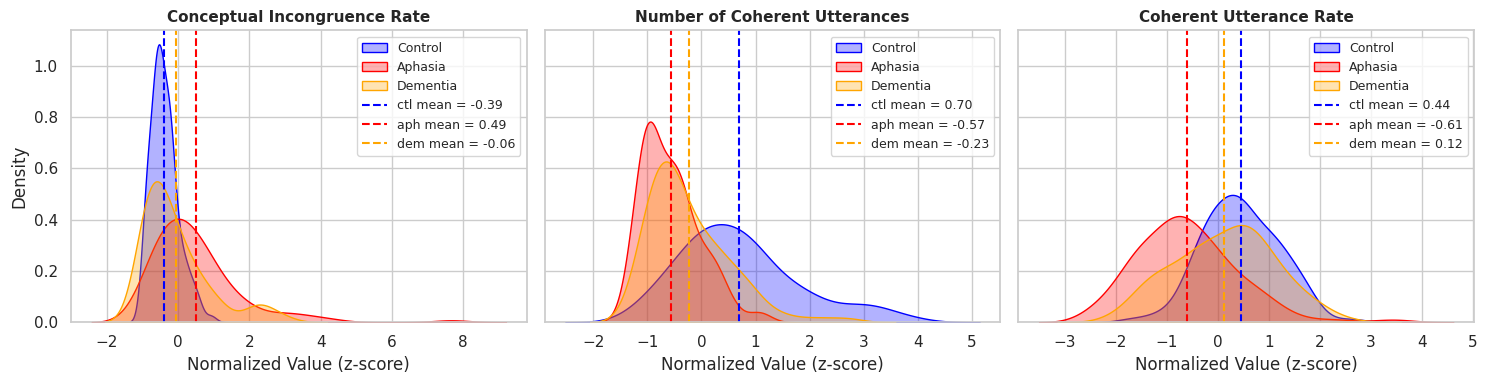

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

plots_per_row = 4

for i in range(0, len(num_cols), plots_per_row):
    cols_batch = num_cols[i:i + plots_per_row]

    fig, axes = plt.subplots(
        1, len(cols_batch),
        figsize=(5 * len(cols_batch), 4),
        sharey=True
    )

    # Handle case where there's only one subplot
    if len(cols_batch) == 1:
        axes = [axes]

    for ax, col in zip(axes, cols_batch):

        # ✅ Controls (Blue)
        sns.kdeplot(
            data=ctl_df_z,
            x=col,
            fill=True,
            alpha=0.3,
            color='blue',
            label='Control',
            ax=ax
        )

        # Aphasia (Purple)
        sns.kdeplot(
            data=aph_df_z,
            x=col,
            fill=True,
            alpha=0.3,
            color='red',
            label='Aphasia',
            ax=ax
        )

        # Dementia (Orange)
        sns.kdeplot(
            data=dem_df_z,
            x=col,
            fill=True,
            alpha=0.3,
            color='orange',
            label='Dementia',
            ax=ax
        )

        # ✅ Means
        mean_ctl = ctl_df_z[col].mean()
        mean_aph = aph_df_z[col].mean()
        mean_dem = dem_df_z[col].mean()

        # Control mean
        ax.axvline(
            mean_ctl,
            color='blue',
            linestyle='--',
            linewidth=1.5,
            label=f'ctl mean = {mean_ctl:.2f}'
        )

        # Aphasia mean
        ax.axvline(
            mean_aph,
            color='red',
            linestyle='--',
            linewidth=1.5,
            label=f'aph mean = {mean_aph:.2f}'
        )

        # Dementia mean
        ax.axvline(
            mean_dem,
            color='orange',
            linestyle='--',
            linewidth=1.5,
            label=f'dem mean = {mean_dem:.2f}'
        )
        pretty_name = human_readable_feature(col)
        ax.set_title(pretty_name, fontsize=11, fontweight="bold")

        # ax.set_title(col)
        ax.set_xlabel('Normalized Value (z-score)')
        ax.set_ylabel('Density')

        # Legend
        ax.legend(fontsize=9)

    fig.tight_layout()
    plt.show()


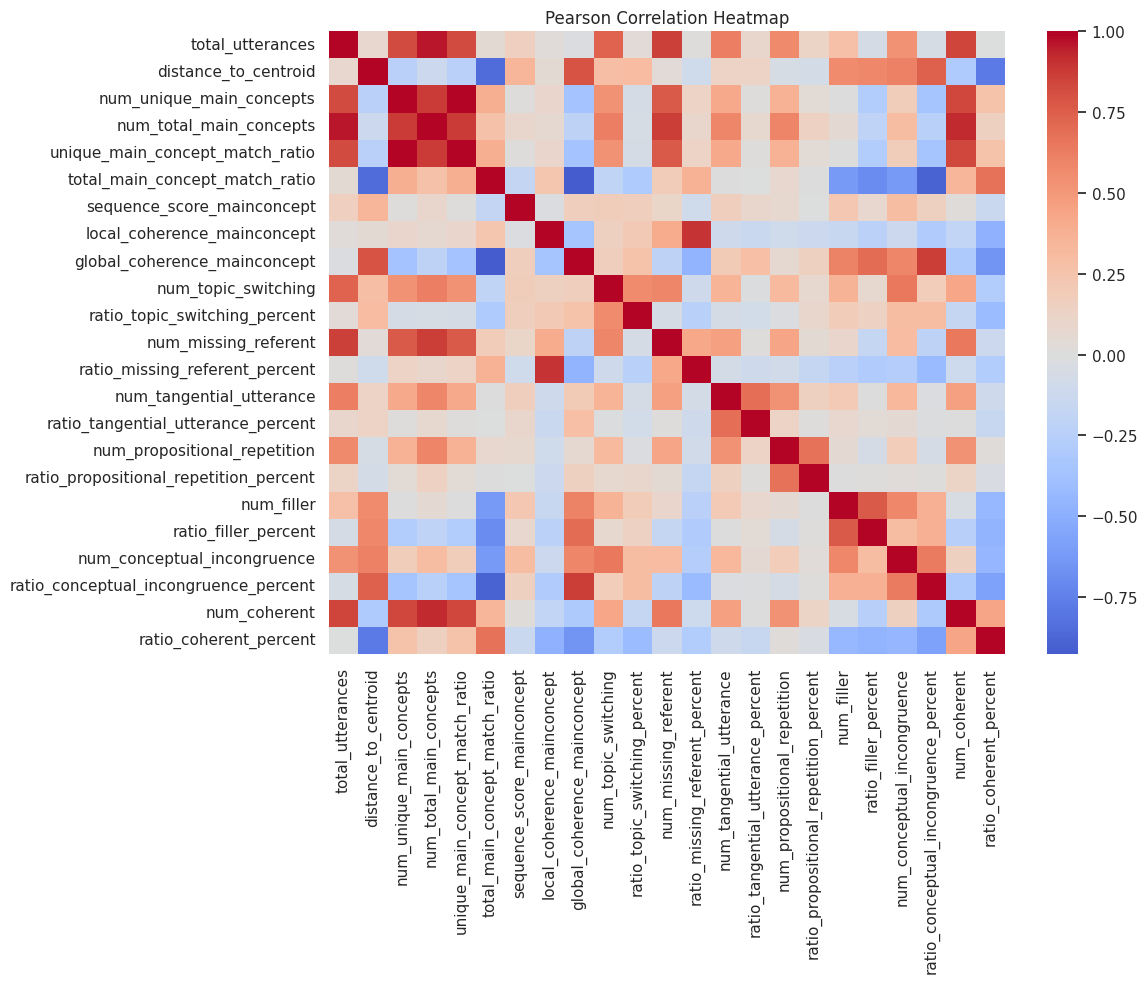

In [25]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Compute Pearson correlation
corr = num_df.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=False, cmap='coolwarm', center=0)
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()

### Load Data for the Logistic Regression Training

In [18]:
import numpy as np

# Take absolute values
corr_abs = corr.abs()

# Mask the diagonal (self correlations)
np.fill_diagonal(corr_abs.values, 0)

# Find pairs above threshold
high_corr_pairs = np.where(corr_abs > 0.8)

pairs = []
for i, j in zip(*high_corr_pairs):
    if i < j:  # avoid duplicates
        pairs.append((
            corr.index[i],
            corr.columns[j],
            corr.iloc[i, j]   # original (signed) correlation value
        ))

for a, b, r in pairs:
    print(f"{a}  <-->  {b}   r = {r:.3f}")

total_utterances  <-->  num_unique_main_concepts   r = 0.819
total_utterances  <-->  num_total_main_concepts   r = 0.956
total_utterances  <-->  unique_main_concept_match_ratio   r = 0.819
total_utterances  <-->  num_missing_referent   r = 0.863
total_utterances  <-->  num_coherent   r = 0.846
distance_to_centroid  <-->  total_main_concept_match_ratio   r = -0.856
num_unique_main_concepts  <-->  num_total_main_concepts   r = 0.877
num_unique_main_concepts  <-->  unique_main_concept_match_ratio   r = 1.000
num_unique_main_concepts  <-->  num_coherent   r = 0.835
num_total_main_concepts  <-->  unique_main_concept_match_ratio   r = 0.877
num_total_main_concepts  <-->  num_missing_referent   r = 0.868
num_total_main_concepts  <-->  num_coherent   r = 0.921
unique_main_concept_match_ratio  <-->  num_coherent   r = 0.835
total_main_concept_match_ratio  <-->  global_coherence_mainconcept   r = -0.905
total_main_concept_match_ratio  <-->  ratio_conceptual_incongruence_percent   r = -0.879
loca

In [42]:
cols_to_remove = []
cols_to_remove.extend([
    "total_utterances",
    "num_unique_main_concepts",
    "num_total_main_concepts",
    "local_coherence_mainconcept",
    "global_coherence_mainconcept",
    "num_coherent",
    # "ratio_conceptual_incongruence_percent",
    "total_main_concept_match_ratio",
])

df_clean = num_df.drop(columns=cols_to_remove, errors="ignore")
feature_cols = df_clean.columns

corr = df_clean.corr(numeric_only=True)

In [43]:
import numpy as np

# Take absolute values
corr_abs = corr.abs()

# Mask the diagonal (self correlations)
np.fill_diagonal(corr_abs.values, 0)

# Find pairs above threshold
high_corr_pairs = np.where(corr_abs > 0.8)

pairs = []
for i, j in zip(*high_corr_pairs):
    if i < j:  # avoid duplicates
        pairs.append((
            corr.index[i],
            corr.columns[j],
            corr.iloc[i, j]   # original (signed) correlation value
        ))

for a, b, r in pairs:
    print(f"{a}  <-->  {b}   r = {r:.3f}")


## Logistic Regression Classification

In [52]:
import re
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    roc_curve,
)

sns.set(style="whitegrid")

# ----------------------------
# CONFIG
# ----------------------------
FOLD_DIR = Path("../data/classification/fold_features_traincutoff_designB")
OUT_DIR = Path("../data/classification/lr_eval_designB")
OUT_DIR.mkdir(parents=True, exist_ok=True)

K = 1.0  # if filenames include k1.0
LR_MAX_ITER = 5000

# Match your label strings in the fold CSVs
LABEL_TO_INT = {"controls": 0, "aphasia": 1, "dementia": 2}
INT_TO_NAME = {0: "Control", 1: "Aphasia", 2: "Dementia"}

pairs = [(0, 1), (0, 2), (1, 2)]  # Control-Aphasia, Control-Dementia, Aphasia-Dementia

# ----------------------------
# Helpers
# ----------------------------
def find_fold_pairs(folder: Path, k: float):
    """
    Expect files like:
      fold00_train_features_traincutoff_k1.0.csv
      fold00_test_features_traincutoff_k1.0.csv
    """
    train_files = sorted(folder.glob(f"fold*_train_features_traincutoff_k{k}.csv"))
    pairs = []
    for tr in train_files:
        m = re.search(r"fold(\d+)_train_", tr.name)
        if not m:
            continue
        fold = int(m.group(1))
        te = folder / tr.name.replace("_train_", "_test_")
        if te.exists():
            pairs.append((fold, tr, te))
        else:
            print(f"[WARN] missing test for fold {fold}: expected {te}")
    return sorted(pairs, key=lambda x: x[0])


def get_feature_cols(df: pd.DataFrame):
    drop = {"fold", "split", "cutoff_from", "cutoff", "participant", "label"}
    feats = [c for c in df.columns if c not in drop]
    if not feats:
        raise ValueError("No feature columns found (after dropping metadata cols).")
    return feats


def coerce_numeric(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    out = df.copy()
    for c in cols:
        out[c] = pd.to_numeric(out[c], errors="coerce")
    out[cols] = out[cols].fillna(0.0)
    return out


def to_int_labels(label_series: pd.Series) -> np.ndarray:
    y = label_series.map(LABEL_TO_INT)
    if y.isna().any():
        bad = label_series[y.isna()].unique().tolist()
        raise ValueError(f"Unknown label(s) found: {bad}. Expected {list(LABEL_TO_INT)}")
    return y.astype(int).to_numpy()


def plot_cm(cm, labels_int, title, out_png: Path):
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=[INT_TO_NAME[i] for i in labels_int],
        yticklabels=[INT_TO_NAME[i] for i in labels_int],
    )
    plt.title(title)
    plt.ylabel("Actual")
    plt.xlabel("Predicted")
    plt.tight_layout()
    plt.savefig(out_png, dpi=200)
    plt.close()


# ----------------------------
# MAIN
# ----------------------------
def main():
    fold_pairs = find_fold_pairs(FOLD_DIR, K)
    if not fold_pairs:
        raise FileNotFoundError(f"No fold train/test pairs found in {FOLD_DIR} for k={K}")

    # Model: scaler fit on TRAIN only (Pipeline prevents leakage)
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("lr", LogisticRegression(
            multi_class="multinomial",
            solver="lbfgs",
            max_iter=LR_MAX_ITER,
            class_weight="balanced",
        ))
    ])

    # ---------- storage ----------
    y_true_all_3 = []
    y_pred_all_3 = []
    fold_acc_3 = []

    pair_auc = {p: [] for p in pairs}
    pair_fprs = {p: [] for p in pairs}
    pair_tprs = {p: [] for p in pairs}
    mean_fpr = np.linspace(0, 1, 200)
    pair_mean_tpr = {p: np.zeros_like(mean_fpr) for p in pairs}

    pair_y_true_all = {p: [] for p in pairs}
    pair_y_pred_all = {p: [] for p in pairs}
    pair_fold_results = {p: [] for p in pairs}

    pair_coef_folds = {p: [] for p in pairs}
    multi_coef_folds = []  # list of (n_classes, n_features) per fold
    feature_names = None

    print("\n===== CV OVER SAVED FOLDS START =====\n")

    for fold, train_path, test_path in fold_pairs:
        df_train = pd.read_csv(train_path)
        df_test = pd.read_csv(test_path)

        # Use participant IDs for false pos/neg lists
        ids_test = df_test["participant"].astype(str).to_numpy()

        # Features
        all_feats = get_feature_cols(df_train)

        feature_cols = [
            c for c in all_feats
            if c not in cols_to_remove
        ]
        if feature_names is None:
            feature_names = feature_cols
        else:
            # ensure consistent feature order
            missing = [c for c in feature_names if c not in df_train.columns or c not in df_test.columns]
            if missing:
                raise ValueError(f"Fold {fold} missing features: {missing}")

        df_train = coerce_numeric(df_train, feature_names)
        df_test = coerce_numeric(df_test, feature_names)

        X_train = df_train[feature_names]
        X_test = df_test[feature_names]

        y_train = to_int_labels(df_train["label"])
        y_test = to_int_labels(df_test["label"])

        # Fit 1 model per fold
        pipe.fit(X_train, y_train)

        # multiclass preds
        y_pred_3 = pipe.predict(X_test)
        acc_fold = accuracy_score(y_test, y_pred_3)
        fold_acc_3.append(acc_fold)

        y_true_all_3.extend(y_test.tolist())
        y_pred_all_3.extend(y_pred_3.tolist())

        print(f"Fold {fold:02d} 3-class accuracy: {acc_fold:.3f}")

        # probs aligned to lr.classes_
        proba = pipe.predict_proba(X_test)
        lr = pipe.named_steps["lr"]
        classes = lr.classes_

        # store multinomial coefs per fold
        multi_coef_folds.append(lr.coef_.copy())

        # ---- Pairwise metrics from ONE multinomial model ----
        for (i, j) in pairs:
            mask = np.isin(y_test, [i, j])
            if mask.sum() == 0:
                continue

            y_pair_true = y_test[mask]
            ids_pair = ids_test[mask]

            # probability of positive class j
            j_col = np.where(classes == j)[0][0]
            scores_j = proba[mask, j_col]

            # binarize (positive=j)
            y_bin = (y_pair_true == j).astype(int)

            auc_ij = roc_auc_score(y_bin, scores_j)
            pair_auc[(i, j)].append(auc_ij)

            fpr, tpr, _ = roc_curve(y_bin, scores_j)
            pair_fprs[(i, j)].append(fpr)
            pair_tprs[(i, j)].append(tpr)
            pair_mean_tpr[(i, j)] += np.interp(mean_fpr, fpr, tpr)
            pair_mean_tpr[(i, j)][0] = 0.0

            # pairwise predicted labels using probs restricted to {i, j}
            i_col = np.where(classes == i)[0][0]
            probs_ij = proba[mask][:, [i_col, j_col]]
            pred_pair = np.array([i, j])[np.argmax(probs_ij, axis=1)]

            pair_y_true_all[(i, j)].extend(y_pair_true.tolist())
            pair_y_pred_all[(i, j)].extend(pred_pair.tolist())

            # FP/FN relative to positive=j
            fn_mask = (y_pair_true == j) & (pred_pair == i)  # true j predicted i
            fp_mask = (y_pair_true == i) & (pred_pair == j)  # true i predicted j

            pair_fold_results[(i, j)].append({
                "fold": fold,
                "false_negatives": ids_pair[fn_mask].tolist(),
                "false_positives": ids_pair[fp_mask].tolist(),
            })

            # directional coefficients: w_j - w_i
            wj = lr.coef_[np.where(classes == j)[0][0]]
            wi = lr.coef_[np.where(classes == i)[0][0]]
            pair_coef_folds[(i, j)].append(wj - wi)

        # Save fold confusion matrix (3-class) for this fold
        cm_fold = confusion_matrix(y_test, y_pred_3, labels=[0, 1, 2])
        plot_cm(
            cm_fold, [0, 1, 2],
            title=f"3-Class Confusion (Fold {fold:02d})",
            out_png=OUT_DIR / f"fold{fold:02d}_cm_3class.png"
        )

    print("\n===== CV OVER SAVED FOLDS DONE =====\n")

    # ----------------------------
    # 1) 3-class accuracy summary
    # ----------------------------
    acc_summary = pd.DataFrame({
        "fold": [f for f, _, _ in fold_pairs],
        "acc_3class": fold_acc_3,
    })
    acc_summary.to_csv(OUT_DIR / "fold_accuracy_3class.csv", index=False)

    print("===== 3-CLASS ACCURACY =====")
    print("Accuracy per fold:", np.round(fold_acc_3, 3))
    print(f"Mean accuracy: {np.mean(fold_acc_3):.3f}")
    print(f"Std accuracy:  {np.std(fold_acc_3):.3f}")

    # ----------------------------
    # 2) Global 3-class confusion (all folds combined)
    # ----------------------------
    cm3 = confusion_matrix(y_true_all_3, y_pred_all_3, labels=[0, 1, 2])
    plot_cm(
        cm3, [0, 1, 2],
        title="3-Class Confusion Matrix (All Test Folds Combined)",
        out_png=OUT_DIR / "cm_3class_allfolds.png"
    )

    cm3_df = pd.DataFrame(cm3, index=["true_C", "true_A", "true_D"], columns=["pred_C", "pred_A", "pred_D"])
    cm3_df.to_csv(OUT_DIR / "cm_3class_allfolds.csv", index=True)

    # ----------------------------
    # 3) Pairwise ROC curves (mean across folds) + AUC per fold
    # ----------------------------
    roc_rows = []
    for (i, j) in pairs:
        if len(pair_auc[(i, j)]) == 0:
            continue

        mean_tpr = pair_mean_tpr[(i, j)] / len(pair_auc[(i, j)])
        mean_tpr[-1] = 1.0
        mean_auc = float(np.mean(pair_auc[(i, j)]))

        # Save AUC per fold
        roc_rows.append({
            "pair": f"{INT_TO_NAME[i]} vs {INT_TO_NAME[j]}",
            "mean_auc": mean_auc,
            "auc_per_fold": pair_auc[(i, j)],
        })

        # Plot ROC
        plt.figure(figsize=(6, 5))
        for k, (fpr, tpr) in enumerate(zip(pair_fprs[(i, j)], pair_tprs[(i, j)]), start=1):
            plt.plot(fpr, tpr, alpha=0.25, label=f"Fold {k} AUC={pair_auc[(i, j)][k-1]:.2f}")
        plt.plot(mean_fpr, mean_tpr, linewidth=2, label=f"Mean ROC (AUC={mean_auc:.3f})")
        plt.plot([0, 1], [0, 1], linestyle="--")

        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.title(f"ROC (OvO) — {INT_TO_NAME[i]} vs {INT_TO_NAME[j]}")
        plt.legend(loc="lower right")
        plt.tight_layout()
        plt.savefig(OUT_DIR / f"roc_{i}vs{j}.png", dpi=200)
        plt.close()

    # Save pairwise ROC/AUC summary
    # (auc_per_fold is a list; keep it as a string for csv)
    roc_df = pd.DataFrame(roc_rows)
    if len(roc_df) > 0:
        roc_df["auc_per_fold"] = roc_df["auc_per_fold"].apply(lambda x: ",".join([f"{v:.4f}" for v in x]))
        roc_df.to_csv(OUT_DIR / "pairwise_auc_summary.csv", index=False)

    # ----------------------------
    # 4) Pairwise global confusion matrices + FP/FN participant IDs per fold
    # ----------------------------
    for (i, j) in pairs:
        yt = pair_y_true_all[(i, j)]
        yp = pair_y_pred_all[(i, j)]
        if len(yt) == 0:
            continue

        cm = confusion_matrix(yt, yp, labels=[i, j])
        cm_df = pd.DataFrame(
            cm,
            index=[f"true_{INT_TO_NAME[i]}", f"true_{INT_TO_NAME[j]}"],
            columns=[f"pred_{INT_TO_NAME[i]}", f"pred_{INT_TO_NAME[j]}"]
        )
        cm_df.to_csv(OUT_DIR / f"cm_pair_{i}vs{j}_allfolds.csv", index=True)

        # plot
        plt.figure(figsize=(5, 4))
        sns.heatmap(
            cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[f"Pred {INT_TO_NAME[i]}", f"Pred {INT_TO_NAME[j]}"],
            yticklabels=[f"True {INT_TO_NAME[i]}", f"True {INT_TO_NAME[j]}"],
        )
        plt.title(f"Confusion (OvO) — {INT_TO_NAME[i]} vs {INT_TO_NAME[j]}\n(All folds combined)")
        plt.tight_layout()
        plt.savefig(OUT_DIR / f"cm_pair_{i}vs{j}_allfolds.png", dpi=200)
        plt.close()

        # FP/FN IDs per fold
        fpfn_rows = []
        for rec in pair_fold_results[(i, j)]:
            fpfn_rows.append({
                "fold": rec["fold"],
                "pair": f"{INT_TO_NAME[i]} vs {INT_TO_NAME[j]}",
                "false_negatives_true_pos_pred_neg": rec["false_negatives"],  # true j predicted i
                "false_positives_true_neg_pred_pos": rec["false_positives"],  # true i predicted j
            })
        fpfn_df = pd.DataFrame(fpfn_rows)
        fpfn_df.to_json(OUT_DIR / f"fpfn_ids_pair_{i}vs{j}.json", orient="records", indent=2)

    # ----------------------------
    # 5) Pairwise feature importances (direction kept: w_j - w_i), averaged across folds
    # ----------------------------
    TOP_K = 20
    for (i, j) in pairs:
        if len(pair_coef_folds[(i, j)]) == 0:
            continue

        W = np.vstack(pair_coef_folds[(i, j)])  # (n_folds, n_features)
        coef_mean = W.mean(axis=0)              # signed mean
        abs_mean = np.abs(coef_mean)

        imp = pd.DataFrame({
            "feature": feature_names,
            "coef_mean": coef_mean,
            "abs_coef_mean": abs_mean
        }).sort_values("abs_coef_mean", ascending=False)

        imp.to_csv(OUT_DIR / f"pair_{i}vs{j}_coef_mean_allfeatures.csv", index=False)

        top = imp.head(TOP_K).iloc[::-1]

        plt.figure(figsize=(9, 10))
        plt.barh(top["feature"], top["coef_mean"])
        plt.axvline(0, color="black", lw=1)
        plt.xlabel(f"Mean Coef: log(P({INT_TO_NAME[j]}) / P({INT_TO_NAME[i]}))")
        plt.title(f"Pairwise Feature Importances\n{INT_TO_NAME[i]} vs {INT_TO_NAME[j]} (sorted by |coef|)")
        plt.tight_layout()
        plt.savefig(OUT_DIR / f"pair_{i}vs{j}_top{TOP_K}_coef.png", dpi=200)
        plt.close()

    print(f"\n[DONE] All outputs saved under: {OUT_DIR}")


if __name__ == "__main__":
    main()



===== CV OVER SAVED FOLDS START =====

Fold 00 3-class accuracy: 0.532


/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Fold 01 3-class accuracy: 0.694


/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Fold 02 3-class accuracy: 0.597


/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Fold 03 3-class accuracy: 0.597


/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Fold 04 3-class accuracy: 0.623

===== CV OVER SAVED FOLDS DONE =====

===== 3-CLASS ACCURACY =====
Accuracy per fold: [0.532 0.694 0.597 0.597 0.623]
Mean accuracy: 0.608
Std accuracy:  0.052

[DONE] All outputs saved under: ../data/classification/lr_eval_designB


In [56]:
import re
from pathlib import Path
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, roc_auc_score, roc_curve

sns.set(style="whitegrid")

# ========= CONFIG =========
FOLD_DIR = Path("../data/classification/fold_features_traincutoff_designB")
K = 1.0  # match your filenames: ..._k1.0.csv
LR_MAX_ITER = 500

LABEL_TO_INT = {"controls": 0, "aphasia": 1, "dementia": 2}
INT_TO_NAME = {0: "Control", 1: "Aphasia", 2: "Dementia"}

PAIRS = [(0, 1), (0, 2), (1, 2)]


In [57]:
def find_fold_pairs(folder: Path, k: float):
    train_files = sorted(folder.glob(f"fold*_train_features_traincutoff_k{k}.csv"))
    pairs = []
    for tr in train_files:
        m = re.search(r"fold(\d+)_train_", tr.name)
        if not m:
            continue
        fold = int(m.group(1))
        te = folder / tr.name.replace("_train_", "_test_")
        if te.exists():
            pairs.append((fold, tr, te))
        else:
            print(f"[WARN] missing test for fold {fold}: expected {te}")
    return sorted(pairs, key=lambda x: x[0])

def get_feature_cols(df: pd.DataFrame):
    drop = {"fold", "split", "cutoff_from", "cutoff", "participant", "label"}
    feats = [c for c in df.columns if c not in drop]
    if not feats:
        raise ValueError("No feature columns found after dropping metadata cols.")
    return feats

def coerce_numeric(df: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    out = df.copy()
    for c in cols:
        out[c] = pd.to_numeric(out[c], errors="coerce")
    out[cols] = out[cols].fillna(0.0)
    return out

def to_int_labels(labels: pd.Series) -> np.ndarray:
    y = labels.map(LABEL_TO_INT)
    if y.isna().any():
        bad = labels[y.isna()].unique().tolist()
        raise ValueError(f"Unknown label(s): {bad}. Expected {list(LABEL_TO_INT)}")
    return y.astype(int).to_numpy()


In [58]:
fold_pairs = find_fold_pairs(FOLD_DIR, K)
fold_pairs


[(0,
  PosixPath('../data/classification/fold_features_traincutoff_designB/fold00_train_features_traincutoff_k1.0.csv'),
  PosixPath('../data/classification/fold_features_traincutoff_designB/fold00_test_features_traincutoff_k1.0.csv')),
 (1,
  PosixPath('../data/classification/fold_features_traincutoff_designB/fold01_train_features_traincutoff_k1.0.csv'),
  PosixPath('../data/classification/fold_features_traincutoff_designB/fold01_test_features_traincutoff_k1.0.csv')),
 (2,
  PosixPath('../data/classification/fold_features_traincutoff_designB/fold02_train_features_traincutoff_k1.0.csv'),
  PosixPath('../data/classification/fold_features_traincutoff_designB/fold02_test_features_traincutoff_k1.0.csv')),
 (3,
  PosixPath('../data/classification/fold_features_traincutoff_designB/fold03_train_features_traincutoff_k1.0.csv'),
  PosixPath('../data/classification/fold_features_traincutoff_designB/fold03_test_features_traincutoff_k1.0.csv')),
 (4,
  PosixPath('../data/classification/fold_featur

In [59]:
pipe = Pipeline([
    ("scaler", StandardScaler()),  # ✅ fit on TRAIN only
    ("lr", LogisticRegression(
        multi_class="multinomial",
        solver="lbfgs",
        max_iter=LR_MAX_ITER,
        class_weight="balanced"
    ))
])


/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/projectnb/skiran/Cassie/Code/miniconda3/envs/myenv/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:1272: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.8. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/projectnb/skiran/Cass

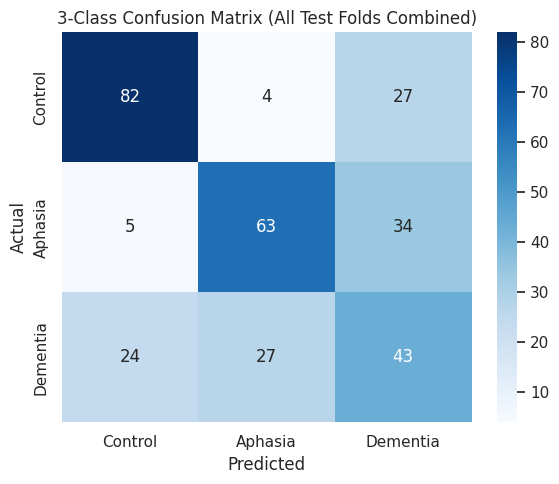

(   fold  acc_3class
 0     0    0.532258
 1     1    0.693548
 2     2    0.596774
 3     3    0.596774
 4     4    0.622951,
    fold                 pair  \
 0     0   Control vs Aphasia   
 1     0  Control vs Dementia   
 2     0  Aphasia vs Dementia   
 3     1   Control vs Aphasia   
 4     1  Control vs Dementia   
 
                    false_negatives_true_pos_pred_neg  \
 0  [Baycrest11154a, UNH14a, fridriksson07a, willi...   
 1                                       [59-1, 68-1]   
 2  [15-1, 20-1, BMN3031b, Baycrest12814, DCR7644a...   
 3                                    [richardson20a]   
 4                           [14-1, 61-1, 64-1, 79-1]   
 
                    false_positives_true_neg_pred_pos       auc  
 0  [delaware03-1, delaware203-1, delaware227-1, d...  0.871739  
 1  [delaware03-1, delaware203-1, delaware227-1, d...  0.581236  
 2  [Baycrest11154a, Baycrest12288a, MMA19a, UNH14...  0.547368  
 3                      [delaware208-1, delaware65-1]  0.972789  

In [62]:
# storage
y_true_all_3, y_pred_all_3 = [], []
fold_acc_3 = []

pair_auc = {p: [] for p in PAIRS}
pair_fprs = {p: [] for p in PAIRS}
pair_tprs = {p: [] for p in PAIRS}
mean_fpr = np.linspace(0, 1, 200)
pair_mean_tpr = {p: np.zeros_like(mean_fpr) for p in PAIRS}

pair_y_true_all = {p: [] for p in PAIRS}
pair_y_pred_all = {p: [] for p in PAIRS}
pair_fpfn_rows = []  # flattened rows for a nice dataframe

pair_coef_folds = {p: [] for p in PAIRS}
multi_coef_folds = []
feature_names = None

from sklearn.metrics import confusion_matrix
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

class_names = {0:"Control", 1:"Aphasia", 2:"Dementia"}

y_true_all_3 = []
y_pred_all_3 = []


for fold, train_path, test_path in fold_pairs:
    df_train = pd.read_csv(train_path)
    df_test  = pd.read_csv(test_path)

    # participant IDs in test for FP/FN tracking
    ids_test = df_test["participant"].astype(str).to_numpy()

    all_feats = get_feature_cols(df_train)

    feat_cols = [
        c for c in all_feats
        if c not in cols_to_remove
    ]
    if feature_names is None:
        feature_names = feat_cols
    else:
        # enforce consistent features
        missing = [c for c in feature_names if c not in df_train.columns or c not in df_test.columns]
        if missing:
            raise ValueError(f"Fold {fold} missing features: {missing}")

    df_train = coerce_numeric(df_train, feature_names)
    df_test  = coerce_numeric(df_test, feature_names)

    X_train = df_train[feature_names]
    X_test  = df_test[feature_names]
    y_train = to_int_labels(df_train["label"])
    y_test  = to_int_labels(df_test["label"])

    # fit + predict
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    fold_acc_3.append(acc)

    y_true_all_3.extend(y_test.tolist())
    y_pred_all_3.extend(y_pred.tolist())
    

    # proba + coefs
    proba = pipe.predict_proba(X_test)
    lr = pipe.named_steps["lr"]
    classes = lr.classes_
    multi_coef_folds.append(lr.coef_.copy())

    # pairwise metrics from this one model
    for (i, j) in PAIRS:
        mask = np.isin(y_test, [i, j])
        if mask.sum() == 0:
            continue

        y_pair_true = y_test[mask]
        ids_pair = ids_test[mask]

        j_col = np.where(classes == j)[0][0]
        i_col = np.where(classes == i)[0][0]

        scores_j = proba[mask, j_col]
        y_bin = (y_pair_true == j).astype(int)

        auc_ij = roc_auc_score(y_bin, scores_j)
        pair_auc[(i, j)].append(auc_ij)

        fpr, tpr, _ = roc_curve(y_bin, scores_j)
        pair_fprs[(i, j)].append(fpr)
        pair_tprs[(i, j)].append(tpr)
        pair_mean_tpr[(i, j)] += np.interp(mean_fpr, fpr, tpr)
        pair_mean_tpr[(i, j)][0] = 0.0

        probs_ij = proba[mask][:, [i_col, j_col]]
        pred_pair = np.array([i, j])[np.argmax(probs_ij, axis=1)]

        pair_y_true_all[(i, j)].extend(y_pair_true.tolist())
        pair_y_pred_all[(i, j)].extend(pred_pair.tolist())

        fn_mask = (y_pair_true == j) & (pred_pair == i)
        fp_mask = (y_pair_true == i) & (pred_pair == j)

        pair_fpfn_rows.append({
            "fold": fold,
            "pair": f"{INT_TO_NAME[i]} vs {INT_TO_NAME[j]}",
            "false_negatives_true_pos_pred_neg": ids_pair[fn_mask].tolist(),  # true j predicted i
            "false_positives_true_neg_pred_pos": ids_pair[fp_mask].tolist(),  # true i predicted j
            "auc": auc_ij,
        })

        # directional coef w_j - w_i
        wj = lr.coef_[np.where(classes == j)[0][0]]
        wi = lr.coef_[np.where(classes == i)[0][0]]
        pair_coef_folds[(i, j)].append(wj - wi)

labels_order = [0, 1, 2]  # Control, Aphasia, Dementia

cm3 = confusion_matrix(y_true_all_3, y_pred_all_3, labels=labels_order)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm3,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[class_names[k] for k in labels_order],
    yticklabels=[class_names[k] for k in labels_order],
)
plt.title("3-Class Confusion Matrix (All Test Folds Combined)")
plt.ylabel("Actual")
plt.xlabel("Predicted")
plt.tight_layout()
plt.show()


acc_df = pd.DataFrame({"fold": [f for f,_,_ in fold_pairs], "acc_3class": fold_acc_3})
fpfn_df = pd.DataFrame(pair_fpfn_rows)

acc_df, fpfn_df.head()


In [61]:
rows = []
for (i, j) in PAIRS:
    if len(pair_auc[(i,j)]) == 0:
        continue
    rows.append({
        "pair": f"{INT_TO_NAME[i]} vs {INT_TO_NAME[j]}",
        "auc_mean": float(np.mean(pair_auc[(i,j)])),
        "auc_std": float(np.std(pair_auc[(i,j)])),
        "auc_per_fold": pair_auc[(i,j)],
    })

pair_auc_df = pd.DataFrame(rows)
display(pair_auc_df)


,pair,auc_mean,auc_std,auc_per_fold
0,Control vs Aphasia,0.923699,0.038158,"[0.8717391304347826, 0.9727891156462585, 0.936..."
1,Control vs Dementia,0.671002,0.071151,"[0.5812356979405033, 0.7833333333333333, 0.707..."
2,Aphasia vs Dementia,0.559576,0.082173,"[0.5473684210526315, 0.6952380952380953, 0.521..."


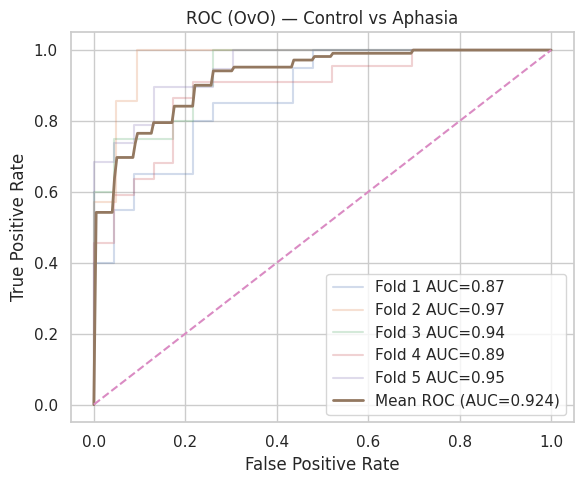

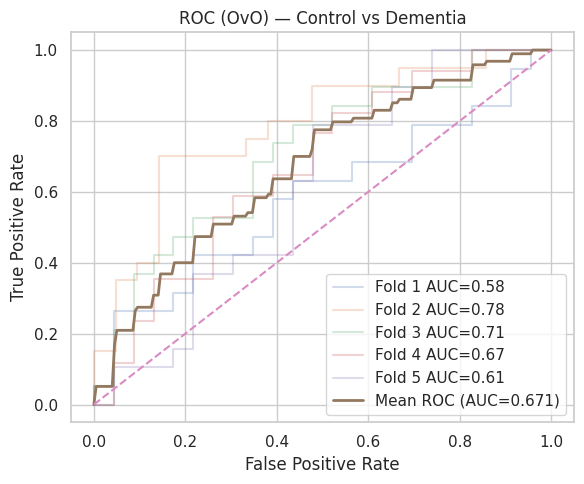

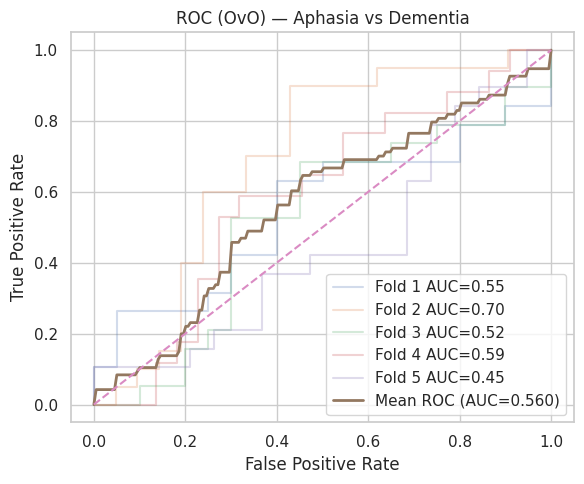

In [46]:
for (i, j) in PAIRS:
    if len(pair_auc[(i,j)]) == 0:
        continue

    mean_tpr = pair_mean_tpr[(i,j)] / len(pair_auc[(i,j)])
    mean_tpr[-1] = 1.0
    mean_auc = float(np.mean(pair_auc[(i,j)]))

    plt.figure(figsize=(6,5))
    for k, (fpr, tpr) in enumerate(zip(pair_fprs[(i,j)], pair_tprs[(i,j)]), start=1):
        plt.plot(fpr, tpr, alpha=0.25, label=f"Fold {k} AUC={pair_auc[(i,j)][k-1]:.2f}")

    plt.plot(mean_fpr, mean_tpr, linewidth=2, label=f"Mean ROC (AUC={mean_auc:.3f})")
    plt.plot([0,1],[0,1], linestyle="--")

    plt.title(f"ROC (OvO) — {INT_TO_NAME[i]} vs {INT_TO_NAME[j]}")
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend(loc="lower right")
    plt.tight_layout()
    plt.show()


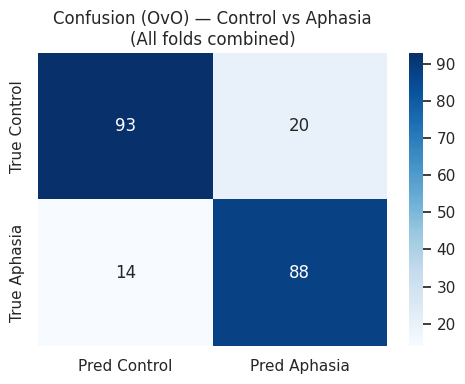

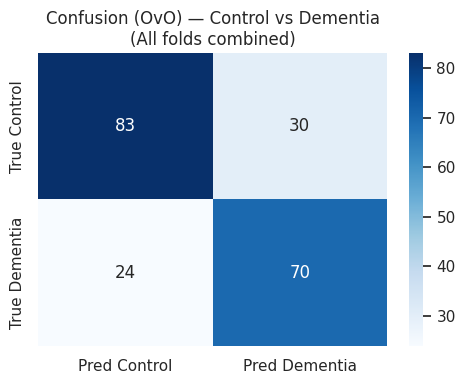

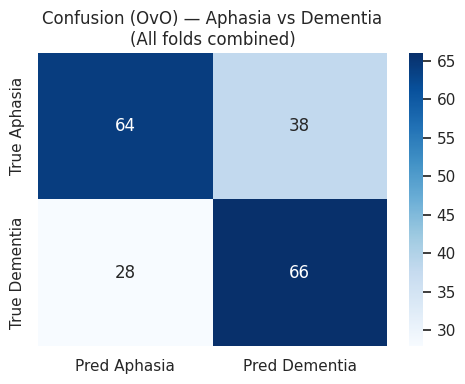

In [47]:
for (i, j) in PAIRS:
    yt = pair_y_true_all[(i,j)]
    yp = pair_y_pred_all[(i,j)]
    if len(yt) == 0:
        continue

    cm = confusion_matrix(yt, yp, labels=[i, j])

    plt.figure(figsize=(5,4))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=[f"Pred {INT_TO_NAME[i]}", f"Pred {INT_TO_NAME[j]}"],
        yticklabels=[f"True {INT_TO_NAME[i]}", f"True {INT_TO_NAME[j]}"],
    )
    plt.title(f"Confusion (OvO) — {INT_TO_NAME[i]} vs {INT_TO_NAME[j]}\n(All folds combined)")
    plt.tight_layout()
    plt.show()


In [48]:
# This shows lists; you can also explode them if you want one ID per row
display(fpfn_df)


,fold,pair,false_negatives_true_pos_pred_neg,false_positives_true_neg_pred_pos,auc
0,0,Control vs Aphasia,"[Baycrest11154a, UNH14a, fridriksson07a, willi...","[delaware03-1, delaware203-1, delaware227-1, d...",0.871739
1,0,Control vs Dementia,"[59-1, 68-1]","[delaware03-1, delaware203-1, delaware227-1, d...",0.581236
2,0,Aphasia vs Dementia,"[15-1, 20-1, BMN3031b, Baycrest12814, DCR7644a...","[Baycrest11154a, Baycrest12288a, MMA19a, UNH14...",0.547368
3,1,Control vs Aphasia,[richardson20a],"[delaware208-1, delaware65-1]",0.972789
4,1,Control vs Dementia,"[14-1, 61-1, 64-1, 79-1]","[delaware208-1, delaware65-1, neural40-1]",0.783333
5,1,Aphasia vs Dementia,"[06-1, 95-1, DRY8487a, JKS7696a, LRW4117a, MVS...","[TAP11a, fridriksson13a, richardson20a, whites...",0.695238
6,2,Control vs Aphasia,[adler03a],"[delaware221-1, delaware30-1, delaware46-1, ne...",0.936957
7,2,Control vs Dementia,"[16-1, 21-1, 43-1, 66-1, 74-1]","[delaware07-1, delaware221-1, delaware30-1, de...",0.707094
8,2,Aphasia vs Dementia,"[50-1, AMR6628a, Baycrest12756, MJE8703a, PON4...","[Baycrest12072a, MMA14a, acwt04a, adler03a, fr...",0.521053
9,3,Control vs Aphasia,"[Baycrest12331a, Baycrest9772a, MMA11a, richar...","[delaware05-1, delaware270-1, wright06a, wrigh...",0.887352


In [49]:
fpfn_exploded = fpfn_df.copy()
fpfn_exploded["false_negatives_true_pos_pred_neg"] = fpfn_exploded["false_negatives_true_pos_pred_neg"].apply(lambda x: x if isinstance(x, list) else [])
fpfn_exploded["false_positives_true_neg_pred_pos"] = fpfn_exploded["false_positives_true_neg_pred_pos"].apply(lambda x: x if isinstance(x, list) else [])

fn_rows = fpfn_exploded[["fold","pair","auc","false_negatives_true_pos_pred_neg"]].explode("false_negatives_true_pos_pred_neg")
fn_rows = fn_rows.rename(columns={"false_negatives_true_pos_pred_neg":"participant"}).dropna(subset=["participant"])

fp_rows = fpfn_exploded[["fold","pair","auc","false_positives_true_neg_pred_pos"]].explode("false_positives_true_neg_pred_pos")
fp_rows = fp_rows.rename(columns={"false_positives_true_neg_pred_pos":"participant"}).dropna(subset=["participant"])

display(fn_rows.head(20))
display(fp_rows.head(20))


,fold,pair,auc,participant
0,0,Control vs Aphasia,0.871739,Baycrest11154a
0,0,Control vs Aphasia,0.871739,UNH14a
0,0,Control vs Aphasia,0.871739,fridriksson07a
0,0,Control vs Aphasia,0.871739,williamson07a
1,0,Control vs Dementia,0.581236,59-1
1,0,Control vs Dementia,0.581236,68-1
2,0,Aphasia vs Dementia,0.547368,15-1
2,0,Aphasia vs Dementia,0.547368,20-1
2,0,Aphasia vs Dementia,0.547368,BMN3031b
2,0,Aphasia vs Dementia,0.547368,Baycrest12814


,fold,pair,auc,participant
0,0,Control vs Aphasia,0.871739,delaware03-1
0,0,Control vs Aphasia,0.871739,delaware203-1
0,0,Control vs Aphasia,0.871739,delaware227-1
0,0,Control vs Aphasia,0.871739,delaware86-1
0,0,Control vs Aphasia,0.871739,neural4-1
1,0,Control vs Dementia,0.581236,delaware03-1
1,0,Control vs Dementia,0.581236,delaware203-1
1,0,Control vs Dementia,0.581236,delaware227-1
1,0,Control vs Dementia,0.581236,delaware35-1
1,0,Control vs Dementia,0.581236,delaware86-1


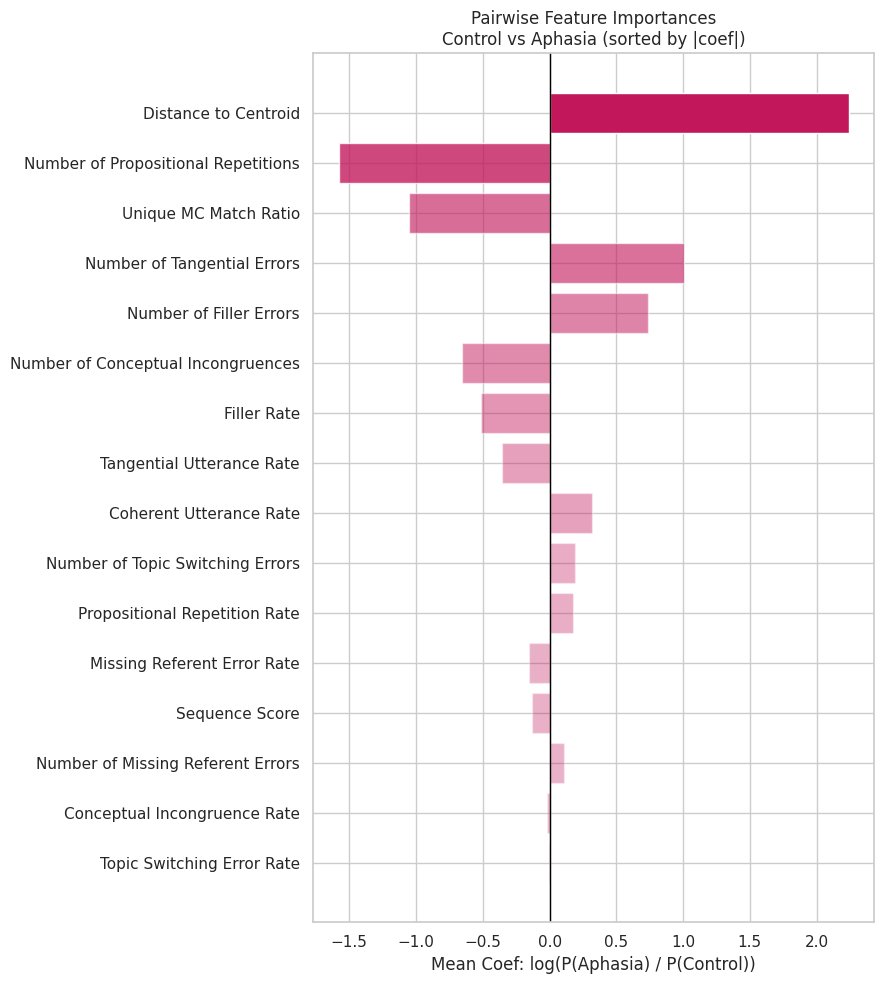

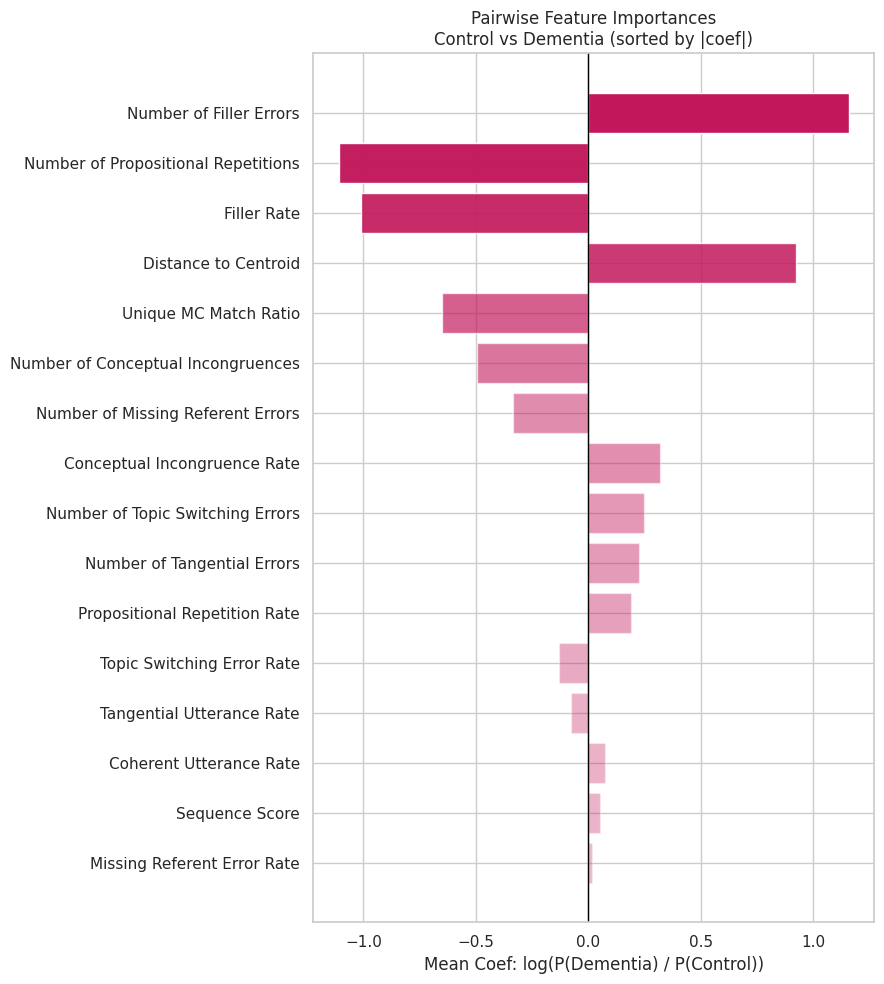

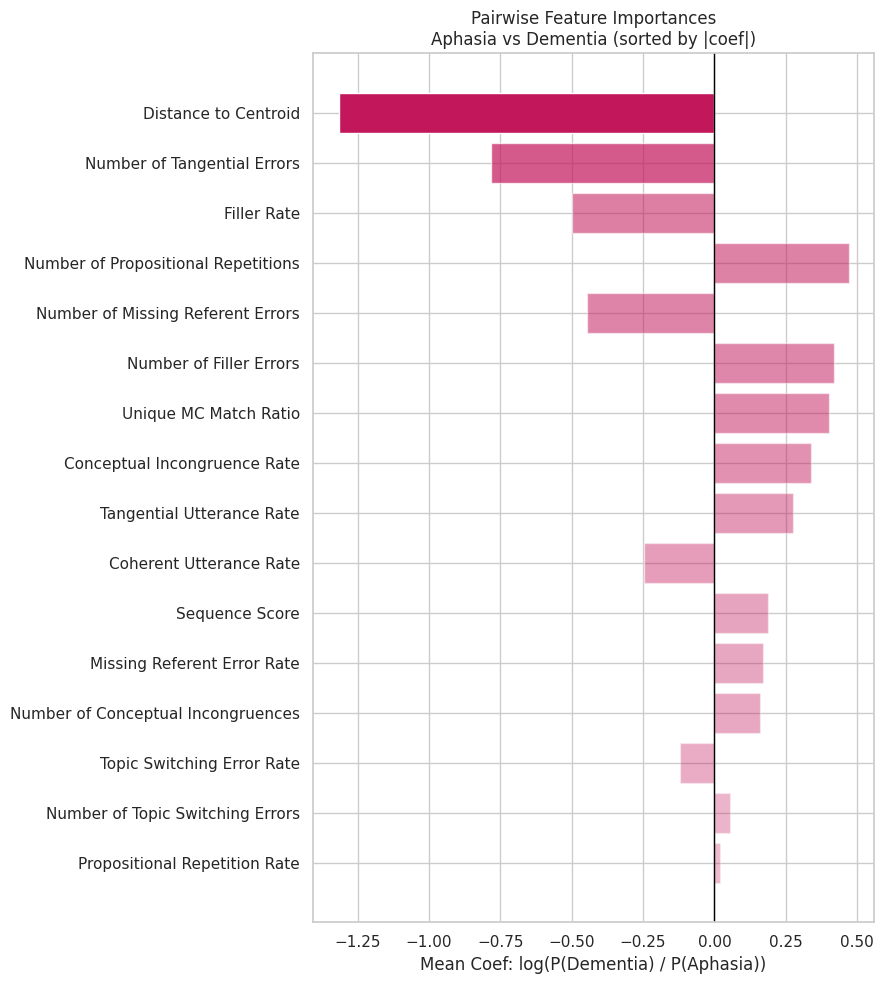

In [63]:
TOP_K = 20

for (i, j) in pairs:

    if len(pair_coef_folds[(i, j)]) == 0:
        continue

    # Stack coefficients
    W = np.vstack(pair_coef_folds[(i, j)])
    coef_mean = W.mean(axis=0)
    abs_mean = np.abs(coef_mean)

    # Build importance DF
    pretty_names = convert_feature_list(feature_names)

    imp = pd.DataFrame({
        "feature": feature_names,
        "feature_pretty": pretty_names,
        "coef_mean": coef_mean,
        "abs_coef_mean": abs_mean
    }).sort_values("abs_coef_mean", ascending=False)

    # Top-K (reverse for barh order)
    top = imp.head(TOP_K).iloc[::-1]

    # ============================
    # Opacity scaling
    # ============================
    mags = top["abs_coef_mean"].to_numpy()

    mags_norm = (mags - mags.min()) / (mags.max() - mags.min() + 1e-9)

    alphas = 0.3 + 0.7 * mags_norm   # [0.3, 1.0]

    # ============================
    # Plot
    # ============================
    plt.figure(figsize=(9, 10))

    bars = plt.barh(
        top["feature_pretty"],   # ✅ readable names
        top["coef_mean"],
        color="#C2185B"
    )

    # Apply opacity
    for bar, a in zip(bars, alphas):
        bar.set_alpha(a)

    plt.axvline(0, color="black", lw=1)

    plt.xlabel(
        f"Mean Coef: log(P({INT_TO_NAME[j]}) / P({INT_TO_NAME[i]}))"
    )

    plt.title(
        f"Pairwise Feature Importances\n"
        f"{INT_TO_NAME[i]} vs {INT_TO_NAME[j]} (sorted by |coef|)"
    )

    plt.tight_layout()
    plt.show()




# TOP_K = 20

# pretty_names = convert_feature_list(feature_names)

# for (i, j) in PAIRS:
#     if len(pair_coef_folds[(i,j)]) == 0:
#         continue

#     W = np.vstack(pair_coef_folds[(i,j)])  # (n_folds, n_features)
#     coef_mean = W.mean(axis=0)
#     abs_mean = np.abs(coef_mean)

#     imp = pd.DataFrame({
#         "feature": feature_names,
#         "feature_pretty": pretty_names,
#         "coef_mean": coef_mean,
#         "abs_coef_mean": abs_mean
#     }).sort_values("abs_coef_mean", ascending=False)

#     display(imp.head(30))

#     top = imp.head(TOP_K).iloc[::-1]
#     plt.figure(figsize=(9,10))
#     plt.barh(top["feature_pretty"], top["coef_mean"])
#     plt.axvline(0, color="black", lw=1)
#     plt.xlabel(f"Mean coef: log(P({INT_TO_NAME[j]}) / P({INT_TO_NAME[i]}))")
#     plt.title(f"Top {TOP_K} Pairwise Features — {INT_TO_NAME[i]} vs {INT_TO_NAME[j]}")
#     plt.tight_layout()
#     plt.show()
